# Case Study 1: Telco India
## Recruitment Selection Algorithm — Logistic Regression Analysis
**BS in Analytics and Sustainability Studies**  
**Sahil | M2022BSASS023**

---
### Objective
Identify significant attributes from historical candidate data and build a logistic regression-based selection algorithm for Telco India's recruitment process.


---
## Step 1: Install & Import Libraries

In [1]:
# Install required libraries
!pip install pandas numpy scikit-learn matplotlib seaborn openpyxl -q


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, accuracy_score,
    classification_report, roc_curve
)
import warnings
warnings.filterwarnings('ignore')

print('All libraries loaded successfully.')


All libraries loaded successfully.


--- 
## Step 2: Load Dataset
The raw data is the `Raw Data` sheet of `Case1_Analysis.xlsx` in this folder.


In [3]:
df = pd.read_excel('Case1_Analysis.xlsx', sheet_name='Raw Data')
df.columns = [c.strip() for c in df.columns]

print('Dataset Shape:', df.shape)
print('\nFirst 5 rows:')
df.head()


Dataset Shape: (150, 8)

First 5 rows:


,Age,Selection,Gender,Work Experience,Marital Status,College Category,Aptitude Test Score,Distance From Home
0,41,1,1,2,2,1,9,1
1,49,0,1,0,1,2,5,8
2,37,1,1,3,2,1,7,2
3,33,0,2,2,4,2,3,3
4,27,0,1,2,1,2,4,2


---
## Step 3: Exploratory Data Analysis

In [4]:
print('=== Dataset Info ===')
print(df.info())
print('\n=== Missing Values ===')
print(df.isnull().sum())
print('\n=== Selection Distribution ===')
print(df['Selection'].value_counts())
print(f"\nSelected: {df['Selection'].sum()} ({df['Selection'].mean()*100:.1f}%)")
print(f"Not Selected: {(df['Selection']==0).sum()} ({(1-df['Selection'].mean())*100:.1f}%)")


=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Age                  150 non-null    int64
 1   Selection            150 non-null    int64
 2   Gender               150 non-null    int64
 3   Work Experience      150 non-null    int64
 4   Marital Status       150 non-null    int64
 5   College Category     150 non-null    int64
 6   Aptitude Test Score  150 non-null    int64
 7   Distance From Home   150 non-null    int64
dtypes: int64(8)
memory usage: 9.5 KB
None

=== Missing Values ===
Age                    0
Selection              0
Gender                 0
Work Experience        0
Marital Status         0
College Category       0
Aptitude Test Score    0
Distance From Home     0
dtype: int64

=== Selection Distribution ===
Selection
0    123
1     27
Name: count, dtype: int64

Selected: 27 (18.0%)
Not Selected: 123 

In [5]:
# Descriptive statistics by selection outcome
print('=== Mean Values: Selected vs Not Selected ===')
df.groupby('Selection').mean().T.rename(columns={0: 'Not Selected', 1: 'Selected'})


=== Mean Values: Selected vs Not Selected ===


Selection,Not Selected,Selected
Age,37.349593,35.518519
Gender,1.414634,1.296296
Work Experience,1.495935,2.333333
Marital Status,2.869919,2.777778
College Category,1.918699,1.407407
Aptitude Test Score,4.000000,5.703704
Distance From Home,9.048780,9.518519


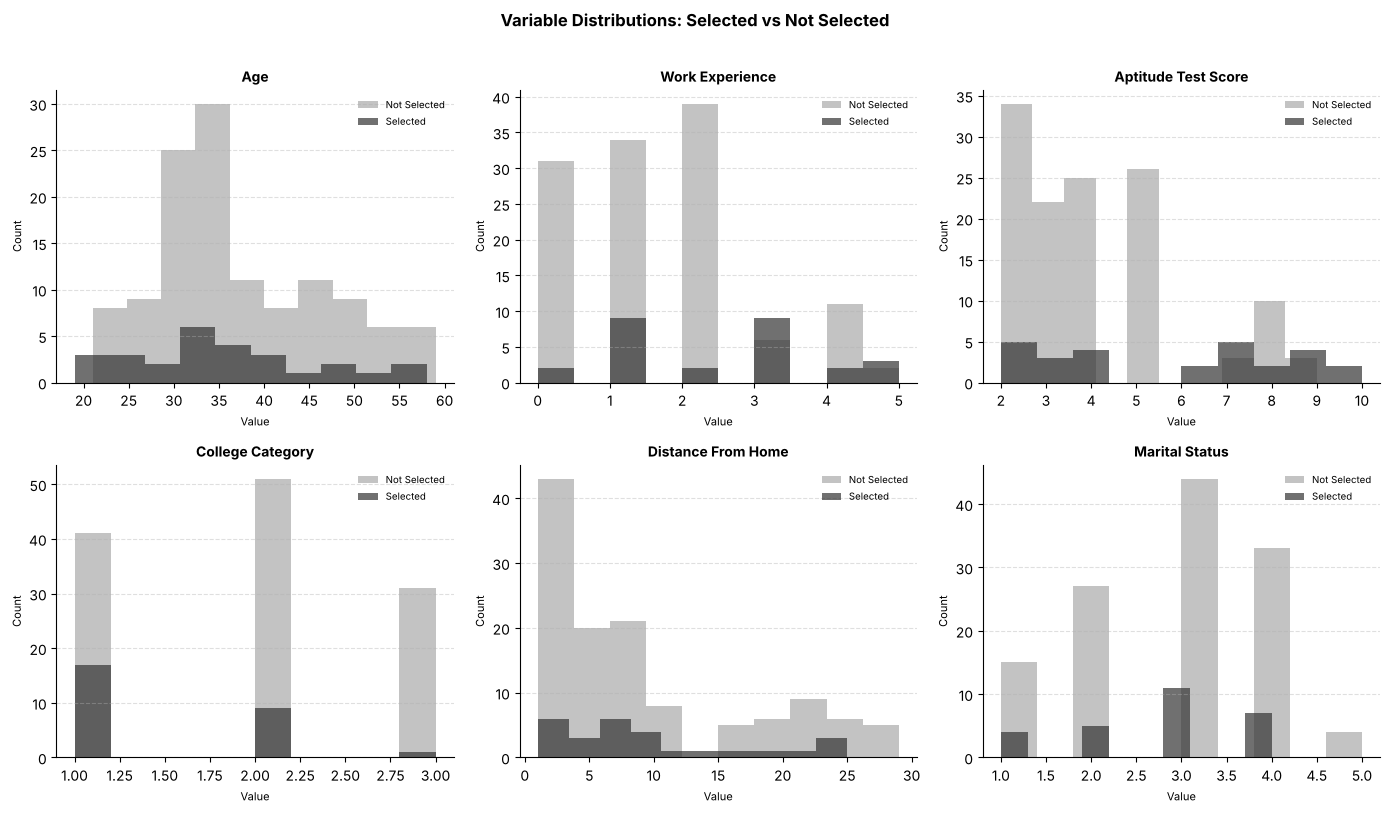

In [6]:
# Visualize key variable distributions
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
cols_to_plot = ['Age', 'Work Experience', 'Aptitude Test Score',
                'College Category', 'Distance From Home', 'Marital Status']

for ax, col in zip(axes, cols_to_plot):
    for sel, label, color in [(0, 'Not Selected', '#AAAAAA'), (1, 'Selected', '#333333')]:
        data = df[df['Selection'] == sel][col]
        ax.hist(data, bins=10, alpha=0.7, label=label, color=color, edgecolor='none')
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.set_xlabel('Value', fontsize=8)
    ax.set_ylabel('Count', fontsize=8)
    ax.legend(fontsize=7, frameon=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.suptitle('Variable Distributions: Selected vs Not Selected', fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


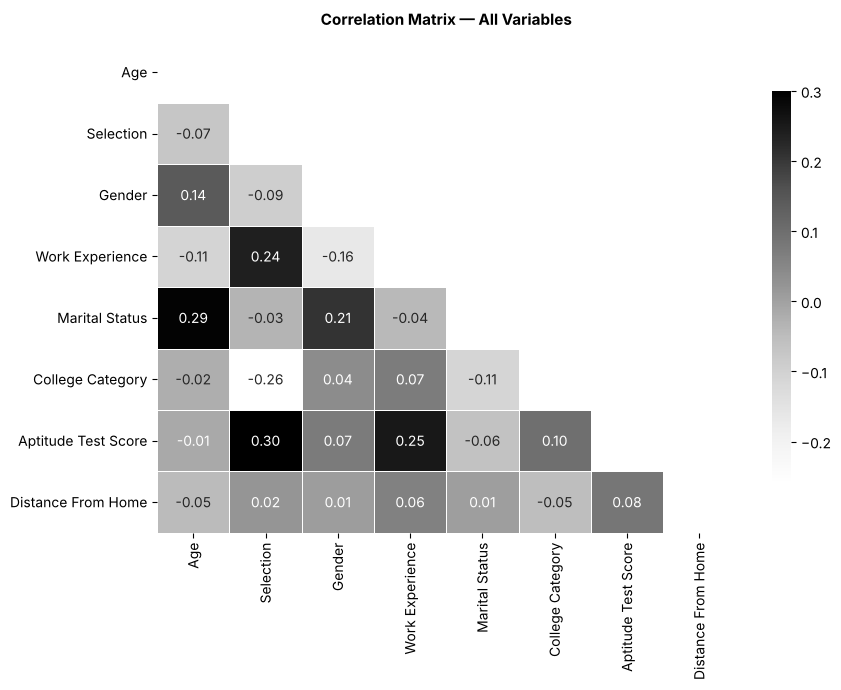

In [7]:
# Correlation heatmap
fig, ax = plt.subplots(figsize=(9, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='Greys',
            linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Matrix — All Variables', fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


---
## Step 4: Preprocessing — Feature Split & Standardization

In [8]:
# Split features and target
X = df.drop('Selection', axis=1)
y = df['Selection']

print('Features (X):', X.columns.tolist())
print('Target (y): Selection')
print('\nFeature shape:', X.shape)
print('Target distribution:\n', y.value_counts())


Features (X): ['Age', 'Gender', 'Work Experience', 'Marital Status', 'College Category', 'Aptitude Test Score', 'Distance From Home']
Target (y): Selection

Feature shape: (150, 7)
Target distribution:
 Selection
0    123
1     27
Name: count, dtype: int64


In [9]:
# Standardize features — necessary because variables are on different scales
# Without this, Distance From Home (values up to 100+) would dominate over
# Aptitude Score (values 2-10) purely due to numeric magnitude
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Standardization complete.')
print('Mean of scaled features (should be ~0):', X_scaled.mean(axis=0).round(4))
print('Std of scaled features (should be ~1):', X_scaled.std(axis=0).round(4))


Standardization complete.
Mean of scaled features (should be ~0): [-0.  0.  0. -0.  0.  0.  0.]
Std of scaled features (should be ~1): [1. 1. 1. 1. 1. 1. 1.]


---
## Step 5: Logistic Regression Model

In [10]:
# Fit logistic regression
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_scaled, y)

# Predictions
y_pred = model.predict(X_scaled)
y_prob = model.predict_proba(X_scaled)[:, 1]

print('Model fitted successfully.')
print(f'Intercept: {model.intercept_[0]:.4f}')


Model fitted successfully.
Intercept: -2.0309


In [11]:
# Coefficient table with odds ratios
coef_df = pd.DataFrame({
    'Variable': X.columns,
    'Coefficient (β)': model.coef_[0].round(4),
    'Odds Ratio (eβ)': np.exp(model.coef_[0]).round(4)
}).sort_values('Coefficient (β)', ascending=False).reset_index(drop=True)

print('=== Logistic Regression Coefficients ===')
coef_df


=== Logistic Regression Coefficients ===


,Variable,Coefficient (β),Odds Ratio (eβ)
0,Aptitude Test Score,0.8038,2.2340
1,Work Experience,0.4749,1.6078
2,Marital Status,0.0078,1.0078
3,Distance From Home,-0.0017,0.9983
4,Age,-0.1539,0.8574
5,Gender,-0.2168,0.8051
6,College Category,-1.0290,0.3573


---
## Step 6: Model Evaluation

In [12]:
acc = accuracy_score(y, y_pred)
auc = roc_auc_score(y, y_prob)
cm = confusion_matrix(y, y_pred)

print(f'Accuracy  : {acc:.4f} ({acc*100:.2f}%)')
print(f'AUC-ROC   : {auc:.4f}')
print('\nClassification Report:')
print(classification_report(y, y_pred, target_names=['Not Selected', 'Selected']))


Accuracy  : 0.8800 (88.00%)
AUC-ROC   : 0.8058

Classification Report:
              precision    recall  f1-score   support

Not Selected       0.89      0.98      0.93       123
    Selected       0.80      0.44      0.57        27

    accuracy                           0.88       150
   macro avg       0.84      0.71      0.75       150
weighted avg       0.87      0.88      0.87       150



### Out-of-sample check
The figures above are measured on the same candidates the model was trained on. Five-fold stratified cross-validation shows how well the model generalises to new candidates.


In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
cv_scores = cross_validate(pipe, X, y, cv=cv, scoring=['accuracy', 'roc_auc'])

print(f"Cross-validated accuracy : {cv_scores['test_accuracy'].mean():.3f} ± {cv_scores['test_accuracy'].std():.3f}")
print(f"Cross-validated AUC-ROC  : {cv_scores['test_roc_auc'].mean():.3f} ± {cv_scores['test_roc_auc'].std():.3f}")
print(f"Baseline (always predict 'Not Selected'): {1 - y.mean():.3f} accuracy")


Cross-validated accuracy : 0.847 ± 0.016
Cross-validated AUC-ROC  : 0.727 ± 0.135
Baseline (always predict 'Not Selected'): 0.820 accuracy


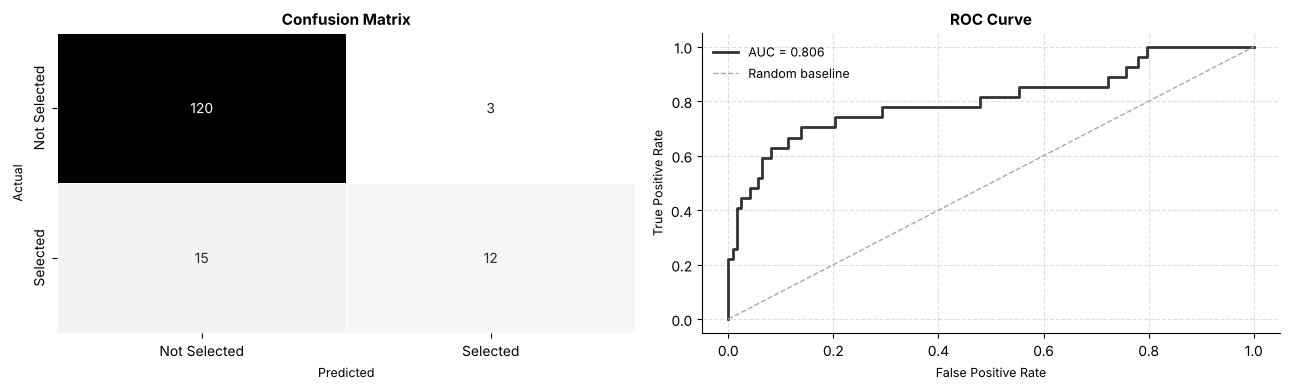

In [14]:
# Confusion matrix heatmap
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Plot 1: Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Greys',
            xticklabels=['Not Selected', 'Selected'],
            yticklabels=['Not Selected', 'Selected'],
            ax=axes[0], linewidths=0.5, cbar=False)
axes[0].set_title('Confusion Matrix', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Predicted', fontsize=9)
axes[0].set_ylabel('Actual', fontsize=9)

# Plot 2: ROC Curve
fpr, tpr, _ = roc_curve(y, y_prob)
axes[1].plot(fpr, tpr, color='#333333', linewidth=2, label=f'AUC = {auc:.3f}')
axes[1].plot([0,1],[0,1], '--', color='#AAAAAA', linewidth=1, label='Random baseline')
axes[1].set_xlabel('False Positive Rate', fontsize=9)
axes[1].set_ylabel('True Positive Rate', fontsize=9)
axes[1].set_title('ROC Curve', fontsize=11, fontweight='bold')
axes[1].legend(fontsize=9, frameon=False)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].grid(linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


---
## Step 7: Key Visualizations

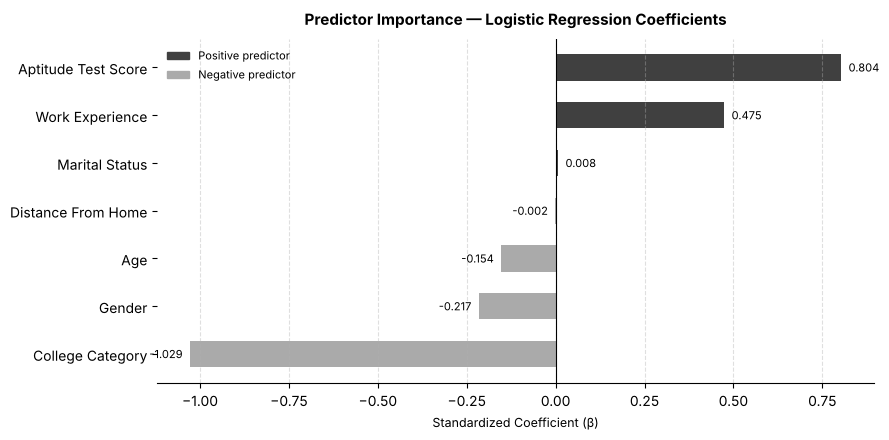

In [15]:
# Coefficient importance chart
sorted_idx = np.argsort(model.coef_[0])
coef_sorted = model.coef_[0][sorted_idx]
vars_sorted = [X.columns[i] for i in sorted_idx]
colors = ['#AAAAAA' if c < 0 else '#404040' for c in coef_sorted]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(vars_sorted, coef_sorted, color=colors, height=0.55, edgecolor='none')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Standardized Coefficient (β)', fontsize=9)
ax.set_title('Predictor Importance — Logistic Regression Coefficients', fontsize=11, fontweight='bold', pad=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.4)
for bar, val in zip(bars, coef_sorted):
    ax.text(val + (0.02 if val >= 0 else -0.02), bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', ha='left' if val >= 0 else 'right', fontsize=8)
pos_p = mpatches.Patch(color='#404040', label='Positive predictor')
neg_p = mpatches.Patch(color='#AAAAAA', label='Negative predictor')
ax.legend(handles=[pos_p, neg_p], fontsize=8, frameon=False)
plt.tight_layout()
plt.show()


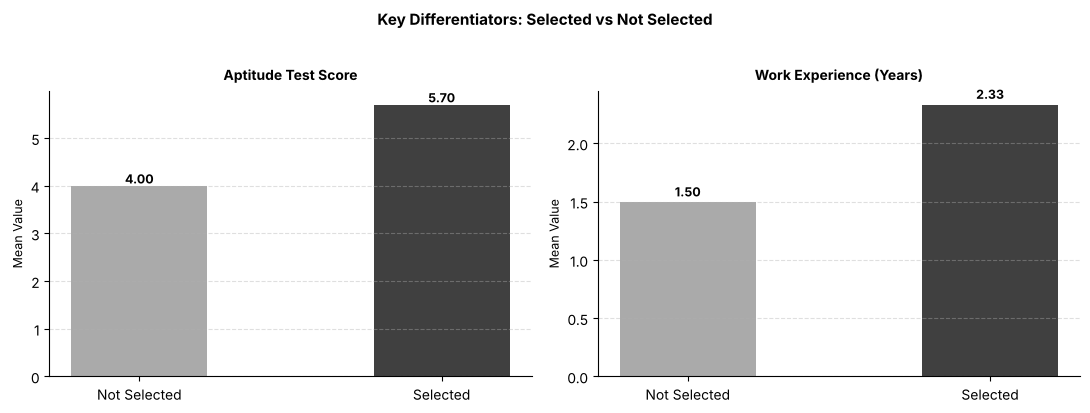

In [16]:
# Selected vs Not Selected: Aptitude & Work Experience
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes,
    ['Aptitude Test Score', 'Work Experience'],
    ['Aptitude Test Score', 'Work Experience (Years)']):
    means = df.groupby('Selection')[col].mean()
    b = ax.bar(['Not Selected', 'Selected'], [means[0], means[1]],
               color=['#AAAAAA', '#404040'], width=0.45, edgecolor='none')
    ax.set_title(title, fontsize=10, fontweight='bold', pad=8)
    ax.set_ylabel('Mean Value', fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    for bar, val in zip(b, [means[0], means[1]]):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.05,
                f'{val:.2f}', ha='center', fontsize=9, fontweight='bold')
plt.suptitle('Key Differentiators: Selected vs Not Selected', fontsize=11, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


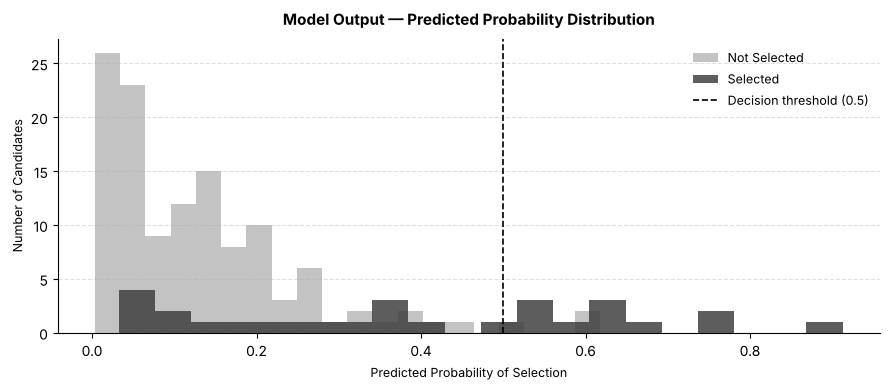

In [17]:
# Predicted probability distribution
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(y_prob[y==0], bins=20, alpha=0.7, color='#AAAAAA', label='Not Selected', edgecolor='none')
ax.hist(y_prob[y==1], bins=20, alpha=0.85, color='#404040', label='Selected', edgecolor='none')
ax.axvline(0.5, color='black', linestyle='--', linewidth=1.2, label='Decision threshold (0.5)')
ax.set_xlabel('Predicted Probability of Selection', fontsize=9)
ax.set_ylabel('Number of Candidates', fontsize=9)
ax.set_title('Model Output — Predicted Probability Distribution', fontsize=11, fontweight='bold', pad=10)
ax.legend(fontsize=9, frameon=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


---
## Step 8: Predict Selection Probability for a New Candidate
Enter candidate details below to get a predicted selection probability.


In [18]:
# Enter new candidate details here
new_candidate = {
    'Age': 28,
    'Gender': 1,               # 1 = Male, 2 = Female
    'Work Experience': 3,      # Years
    'Marital Status': 2,
    'College Category': 1,     # 1 = Tier 1, 2 = Tier 2, 3 = Tier 3
    'Aptitude Test Score': 7,  # Score out of 10
    'Distance From Home': 15   # km
}

candidate_df = pd.DataFrame([new_candidate])
candidate_scaled = scaler.transform(candidate_df)
prob = model.predict_proba(candidate_scaled)[0][1]
decision = 'SELECTED' if prob >= 0.5 else 'NOT SELECTED'

print(f'Predicted Selection Probability : {prob:.4f} ({prob*100:.1f}%)')
print(f'Model Decision                  : {decision}')


Predicted Selection Probability : 0.7070 (70.7%)
Model Decision                  : SELECTED


---
## Summary
| Finding | Detail |
|---|---|
| Model | Logistic Regression |
| Accuracy | 88.00% |
| AUC-ROC | 0.8058 |
| Strongest Predictor | Aptitude Test Score (β = 0.80) |
| Second Strongest | Work Experience (β = 0.47) |
| Variables to Remove | Age, Gender (bias risk, low predictive value) |
| Key Concern | Class imbalance (18% selected) |
